# Week 2 · Rules and decisions

An information system follows rules that people decide. This week you write two of those rules in Python, test them at the edges, and choose the numbers yourself.

| | |
|---|---|
| **This week's question** | How does a system make a decision, and who chooses the rule? |
| **Python you will learn** | comparisons, `True`/`False`, `and`/`or`/`not`, `if`/`elif`/`else`, a first small function |
| **Principle 2** | **Explicit rules.** Name your numbers, cover every case, and test the boundary. |
| **Part you build** | `pickup_label` (hold, team or standard) and `urgency` (urgent, soon or later) |

*Campus FoodBridge is fictional. All organisations, people and numbers are invented.*

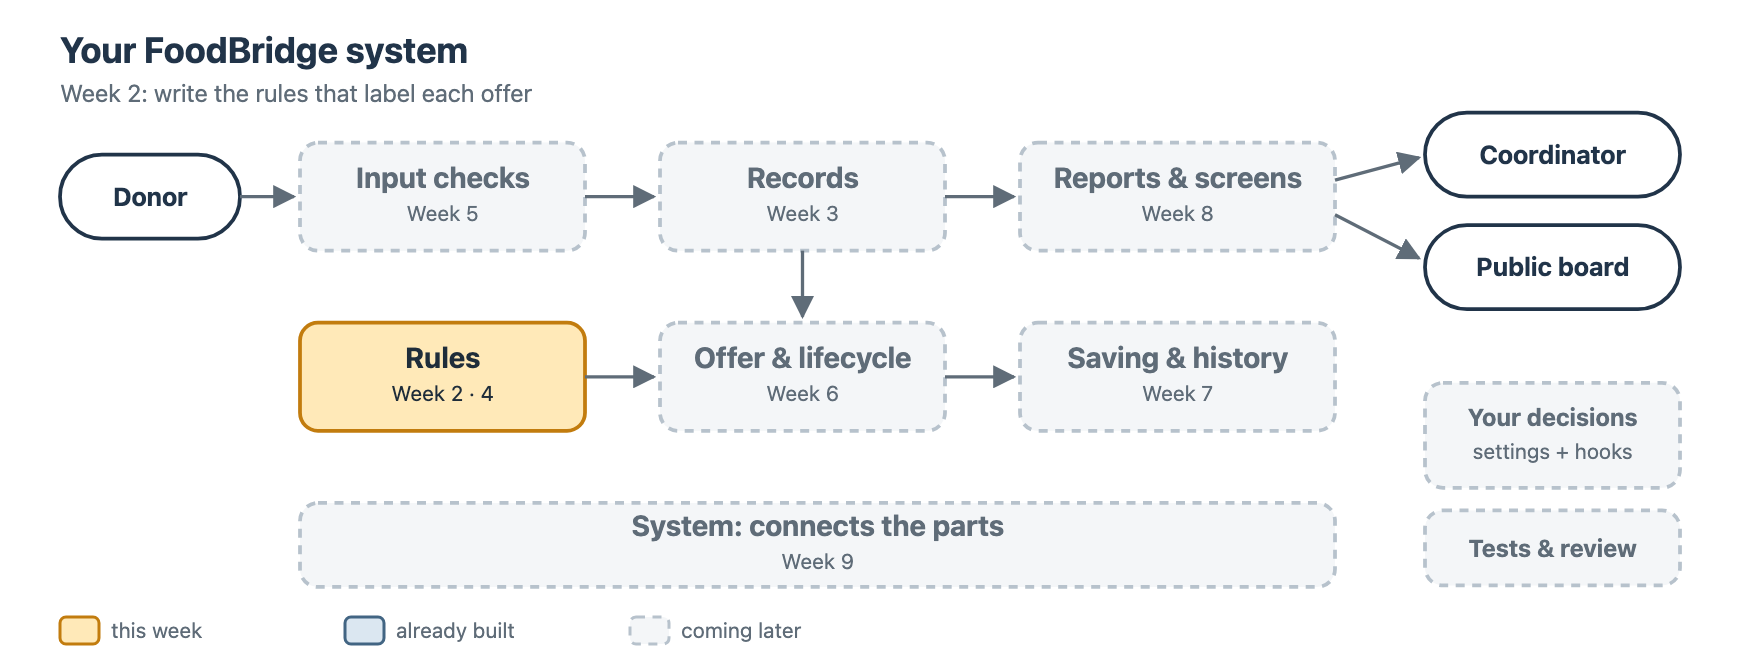

## Before you start

1. **File → Save a copy in Drive**, then work in your copy.
2. Run the setup cell. Run it again after a runtime restart.
3. ⭐ = core for everyone, ⭐⭐ = optional stretch.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the FoodBridge system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
print("✅ FoodBridge system ready (version " + bridge.KIT_VERSION + "). You can continue.")


## Class warm-up · Research 1 exchange (10 min)

In groups of three, share the information system you researched.

1. Who uses it, and what data does it keep?
2. What **rule** did you find? Is the rule written down somewhere, or only in people's heads?
3. What could go wrong, and who would be hurt?

📝 **One idea from a classmate that I want to remember:**

## Session 1 · Learn: how a program decides (30 min)

### The idea: business rules

A **business rule** is a decision an organisation makes about how work is done. Examples: *"An exam mark of 50 or more is a pass."* *"Children under 6 travel free."* In our system the coordinator says:

> *"If an offer is not approved yet, it waits (**hold**). If it is approved and has **20 portions or more**, we send a **team**. Otherwise one volunteer is enough (**standard**)."*

People choose the rule. The program applies it the same way every time, to every offer, at any hour. That is useful, and also dangerous: a wrong rule is applied wrongly every time. So rules must be **written exactly** and **tested at the edges**.

### 1 · Comparisons give `True` or `False`

| Python | Meaning |
|---|---|
| `==` `!=` | equal, not equal |
| `<` `<=` | less than, less than or equal |
| `>` `>=` | greater than, greater than or equal |

🤔 **Predict** each line before you run the cell.

In [ ]:
portions = 20
print(portions >= 20)
print(portions > 20)
print(portions == 20)
print("bread" == "Bread")

**Predictions:** …  **Results:** …  **Surprise:** …

The last line is `False`: text comparison is exact, so capital letters matter. "20 or more" is `>= 20`; "more than 20" is `> 20`. One character changes who gets a team.

### 2 · Combining conditions: `and`, `or`, `not`

In [ ]:
approved = True
portions = 25
print(approved and portions >= 20)   # both must be True
print(not approved)                  # the opposite
print(portions >= 20 or portions < 0)  # at least one must be True

### 3 · `if` and `else`: choosing what to run

In [ ]:
temperature = 31
if temperature >= 30:
    print("Hot: keep the food in the shade")
else:
    print("Normal temperature")
print("This line always runs")

- The line with `if` ends with a colon `:`.
- The lines that belong to it are **indented** by 4 spaces. Indentation is not decoration in Python; it decides what belongs to what.

### 4 · `elif`: more than two choices, checked in order

Python checks the conditions **from top to bottom** and runs only the **first** branch that is `True`.

In [ ]:
mark = 72
if mark >= 80:
    grade = "A"
elif mark >= 65:
    grade = "B"
elif mark >= 50:
    grade = "C"
else:
    grade = "fail"
print(grade)

🤔 What grade does a mark of exactly 65 get? What about 64? Change `mark` and check.

**My answer:** …

### 5 · Name your numbers

A number inside a rule is a **decision**. Give it a name so people can find it, understand it, and change it in one place. By convention, names in CAPITALS are constants: values the program should not change while it runs.

```python
TEAM_PICKUP_MIN_PORTIONS = 20      # decided by the coordinator

if portions >= TEAM_PICKUP_MIN_PORTIONS:
    ...
```

### 6 · A first function: package a rule

A **function** gives a rule a name, takes inputs, and **returns** an answer. You will learn functions properly in Week 4. For now, the pattern is:

In [ ]:
def is_hot(temperature):
    if temperature >= 30:
        return True
    return False

print(is_hot(31))
print(is_hot(25))

- `def` starts the function; `temperature` is its input.
- `return` sends the answer back and **stops** the function.
- You can call the same rule many times with different inputs. That is what the system does for every offer.

## Session 2 · Practise and judge (60 min)

### ⭐ P1 · Predict the comparisons

Write your prediction for each line, then run.

In [ ]:
hours_left = 3
print(hours_left <= 3)
print(hours_left < 3)
print(hours_left != 3)
print(hours_left >= 1 and hours_left <= 12)
print(not hours_left > 12)

**Predictions:** …  **Results:** …

<details><summary>Show a possible answer</summary>

`True`, `False`, `False`, `True`, `True`. The second line is the boundary trap: `3 < 3` is `False`.

</details>

### ⭐ P2 · Repair a boundary bug

The coordinator's rule is *"20 portions **or more** need a team."* This code has a bug. Test it with 19, 20 and 21, find the bug, and fix it.

In [ ]:
def needs_team(portions):
    if portions > 20:
        return True
    return False

print(19, needs_team(19))
print(20, needs_team(20))   # what should this be?
print(21, needs_team(21))

<details><summary>Show a possible answer</summary>

`> 20` must be `>= 20`. Only the **boundary** case (exactly 20) shows the bug; 19 and 21 look fine. This is why we always test the edge, not just a normal value.

</details>

### ⭐ P3 · Repair the order of the branches

Urgency rule: **3 hours or less** is urgent, **12 hours or less** is soon, anything more is later. This version never says "urgent". Why? Fix it by changing the order of the branches.

In [ ]:
def urgency_level(hours_left):
    if hours_left <= 12:
        return "soon"
    elif hours_left <= 3:
        return "urgent"
    else:
        return "later"

print(urgency_level(2), urgency_level(3), urgency_level(4), urgency_level(13))

**Why it never says urgent:** …

<details><summary>Show a possible answer</summary>

2 hours is also `<= 12`, so the first branch wins and the function returns `"soon"` before it ever checks `<= 3`. Put the **narrowest** condition first. Expected after the fix: `urgent urgent soon later`.

</details>

### ⭐ P4 · Write a small rule

A partner kitchen can only accept deliveries of **at most 50 portions**. Write `fits_kitchen(portions)` that returns `True` or `False`. Use a named constant. Test 49, 50 and 51.

In [ ]:
KITCHEN_MAX_PORTIONS = 50

def fits_kitchen(portions):
    # TODO: return True when portions is at most KITCHEN_MAX_PORTIONS
    return None

print(fits_kitchen(49), fits_kitchen(50), fits_kitchen(51))

<details><summary>Show a possible answer</summary>

```python
def fits_kitchen(portions):
    return portions <= KITCHEN_MAX_PORTIONS
```

A comparison already **is** `True` or `False`, so you can return it directly. Expected: `True True False`.

</details>

### ⭐⭐ S1 · Two conditions

Volunteers want a special rule: send a team when an offer is **large (20+) or very urgent (2 hours or less)**, but only if it is approved. Write `send_team(portions, hours_left, approved)` and test four cases of your choice, including one boundary.

In [ ]:
def send_team(portions, hours_left, approved):
    return None   # your rule here

### ⚖️ Good or risky?

An AI assistant wrote **Version A** for the coordinator's rule. **Version B** is a rewrite. Both run without errors.

**Version A**

```python
def label(p, a):
    if p > 20 and a == True:
        return "team"
    elif a == True:
        return "standard"
```

**Version B**

```python
TEAM_PICKUP_MIN_PORTIONS = 20

def pickup_label(portions, approved):
    if not approved:
        return "hold"
    if portions >= TEAM_PICKUP_MIN_PORTIONS:
        return "team"
    return "standard"
```

Use **Principle 2 (explicit rules)**. Find **at least three** problems in Version A. For each one, say which offer would be handled wrongly.

📝 **Problems I found in Version A:**

1.
2.
3.

<details><summary>Instructor's view</summary>

1. **Boundary:** `p > 20` gives exactly 20 portions a standard pickup, against the rule.
2. **Missing case:** when `a` is `False`, nothing is returned, so the function gives `None`, not `"hold"`. The screen would show "None", or the program might crash later.
3. **Hidden decision:** the number 20 is buried inside the code. Nobody can see or change the coordinator's decision without reading the logic.
4. **Names:** `p` and `a` say nothing. (`a == True` also works but is longer than `a`.)

Version B handles every case, puts "not approved" first so it can never be skipped, and names the decision. AI-written code often *looks* finished; judging it means testing the edges and asking "what happens in every case?"

</details>

## Session 3 · Build your part: the pickup rules (60–80 min)

Every offer on the coordinator's screen gets two labels: a **pickup** label (who goes) and an **urgency** label (how soon). Today you write both rules. Then you plug them into the real system: your functions will label every offer.

### Part 1 · `pickup_label`

Rule: not approved → `"hold"`. Approved and at least `TEAM_PICKUP_MIN_PORTIONS` → `"team"`. Otherwise → `"standard"`. Return exactly these lowercase words.

In [ ]:
TEAM_PICKUP_MIN_PORTIONS = 20

def pickup_label(portions, approved):
    # TODO 1: if the offer is not approved, return "hold"
    # TODO 2: if portions is at least TEAM_PICKUP_MIN_PORTIONS, return "team"
    # TODO 3: otherwise return "standard"
    return "?"

Now check it. The checker tries the boundary cases **of your own number**, so it still works when you change the rule later.

In [ ]:
bridge.check("pickup_label", pickup_label, {"TEAM_PICKUP_MIN_PORTIONS": TEAM_PICKUP_MIN_PORTIONS})

### Part 2 · `urgency`

Rule: at most `URGENT_HOURS` → `"urgent"`. At most `SOON_HOURS` → `"soon"`. Otherwise → `"later"`. Remember P3: the order of the branches matters.

In [ ]:
URGENT_HOURS = 3
SOON_HOURS = 12

def urgency(hours_left):
    # TODO: return "urgent", "soon" or "later"
    return "?"

In [ ]:
bridge.check("urgency", urgency, {"URGENT_HOURS": URGENT_HOURS, "SOON_HOURS": SOON_HOURS})

### Part 3 · Plug your rules into the real system

A **hook** is a place where the system lets you plug in your own function. Here you give the system your two rules. Look at the `urgency` and `pickup` columns: they now come from **your** code.

At the end of the sample day, every offer has a decision. So the cell also adds one **new** offer (25 portions, 2 hours left) that nobody has approved yet. Find it in the report: which labels does it get, and why?

In [ ]:
MY_SETTINGS = {
    "TEAM_PICKUP_MIN_PORTIONS": TEAM_PICKUP_MIN_PORTIONS,
    "URGENT_HOURS": URGENT_HOURS,
    "SOON_HOURS": SOON_HOURS,
}
my_system = bridge.System(MY_SETTINGS, hooks={"pickup_label": pickup_label, "urgency": urgency})
my_system.run_day(show=False)
my_system.add_offer({"donor": "Golden Oven Bakery", "contact": "golden@example.org",
                     "food": "Baguettes", "category": "bread", "portions": "25", "hours_left": "2"})
print(my_system.report())

If one of your functions crashes or returns a strange answer, the system prints a ⚠️ warning and uses its own default rule for that offer, so the day can continue. A system people depend on should fail **safely** and **say why**.

🤔 Notice that `MY_SETTINGS` is built **from** your constants instead of repeating the numbers. Why is that safer than typing `20` again?

**My answer:** …

### 🧭 Your decision · when do we send a team, and what is urgent?

The coordinator asks you to suggest the numbers. Think about the people: a team means more volunteers on the road; a standard pickup is one person carrying everything. Urgent offers are collected first.

1. Change `TEAM_PICKUP_MIN_PORTIONS`, `URGENT_HOURS` and `SOON_HOURS` in the cells above (Part 1 and Part 2). You may keep the defaults if you can explain why.
2. Rerun Parts 1–3. The checks still pass, because they use your numbers.
3. Run the cell below to see how your choice changes the work. Every offer gets a label, even a rejected or delivered one, but nobody acts on those: look at the status at the end of each line.

In [ ]:
for offer in my_system.offers:
    print(offer.id, offer.portions, "portions,", offer.hours_left, "hours left →",
          my_system.label(offer), "/", my_system.urgency(offer), "· status:", offer.status)

📝 **Decision log · Week 2**

| | |
|---|---|
| **My choice** | team from … portions; urgent ≤ … hours; soon ≤ … hours |
| **An alternative I considered** | |
| **Why I chose it** | |
| **Who is affected (the tradeoff)** | |

### ⭐⭐ Stretch · explain the decision

People trust a rule more when they can see why it was applied. Write `explain_label(portions, approved)` that returns a sentence such as `"team: 30 portions is at least 20"` or `"hold: waiting for approval"`. Use your constant in the sentence.

In [ ]:
def explain_label(portions, approved):
    return "?"

print(explain_label(30, True))
print(explain_label(12, True))
print(explain_label(30, False))

## Finish

- [ ] I shared my Research 1 finding in the warm-up.
- [ ] I fixed the boundary bug (P2) and the branch-order bug (P3).
- [ ] I found at least three problems in Version A.
- [ ] `pickup_label` and `urgency` pass every check, and the report uses them.
- [ ] My decision log explains my three numbers.

### Research 2 · Rules and edge cases (5%)

Choose a rule from real life: a bus fare for children, a library late fee, a mobile-data bundle, an exam pass mark, a shop discount.

1. Write the rule **exactly**, the way a program would need it.
2. Give a **normal** case, a **boundary** case (exactly at the limit) and an **odd** case (missing, negative or unusual input). Say what should happen in each.
3. Who decides this rule, and who is affected when the boundary is wrong?

Use at least one source and name it. If you use an AI assistant, show one place where you checked or corrected it. Bring your boundary case to the **Week 3 class warm-up**. Submit by email to submit.progmis@gmail.com; the deadline and file name will be announced in class.

**Next week:** one offer is easy. A whole day has many. You will keep one **record** per offer and add them up.